In [44]:
import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import datetime

In [45]:

print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

CUDA Available: True
GPU Name: NVIDIA GeForce RTX 5070 Laptop GPU


In [ ]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [47]:
# Load the training dataset as a NumPy array
# 1. Load the npz archive
# train_file_path = "/home/mathilda/Documents/UCL/machine_learning/comp0245-final/robotnik_arm_task/data/proc/arm_train_proc_20261103_1914.npz"
train_file_path = "/home/mathilda/Documents/UCL/machine_learning/comp0245-final/robotnik_arm_task/data/proc/arm_train_proc_20261103_1931.npz"
train_npz = np.load(train_file_path)
# test_file_path = "/home/mathilda/Documents/UCL/machine_learning/comp0245-final/robotnik_arm_task/data/proc/arm_test_proc_20261103_1914.npz"
test_file_path = "/home/mathilda/Documents/UCL/machine_learning/comp0245-final/robotnik_arm_task/data/proc/arm_test_proc_20261103_1931.npz"
test_npz = np.load(test_file_path)

# 2. Check what array names (keys) are stored inside
# print("Available arrays in file:", train_data.files)

# 3. Extract your specific arrays using their keys
train_data = train_npz["arr"]
train_labels = train_npz["cols"]
test_data = test_npz["arr"]
test_labels = test_npz["cols"]

# Optional: Close the file when done (or use a 'with' block below)
train_npz.close()
test_npz.close()

In [48]:
train_labels
test_labels, len(test_labels)

(array(['ep_id', 'pos_error_x', 'pos_error_y', 'pos_error_z', 'j1_sin',
        'j2_sin', 'j3_sin', 'j4_sin', 'j5_sin', 'j6_sin', 'j7_sin',
        'j1_cos', 'j2_cos', 'j3_cos', 'j4_cos', 'j5_cos', 'j6_cos',
        'j7_cos', 'j1_vel', 'j2_vel', 'j3_vel', 'j4_vel', 'j5_vel',
        'j6_vel', 'j7_vel', 'tau_1', 'tau_2', 'tau_3', 'tau_4', 'tau_5',
        'tau_6', 'tau_7'], dtype='<U11'),
 32)

In [49]:
val_split = int(train_data.shape[0] * 0.8)
val_split

3424205

In [50]:
X_train = train_data[:val_split, 1:-7]  # All columns except the last seven and the first
X_val = train_data[val_split:, 1:-7]  # All columns except the last seven and the first
y_train = train_data[:val_split, -7:]  # Last seven columns
y_val = train_data[val_split:, -7:]  # Last seven columns
X_test = test_data[:, 1:-7]  # All columns except the last seven and the first
y_test = test_data[:, -7:]  # Last seven columns

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

In [51]:
y_train, y_val, y_test
X_train.shape, X_val.shape, X_test.shape

((3424205, 24), (856052, 24), (364727, 24))

In [52]:
X_train_tensor.shape, y_train_tensor.shape, X_val_tensor.shape, y_val_tensor.shape, X_test_tensor.shape, y_test_tensor.shape

(torch.Size([3424205, 24]),
 torch.Size([3424205, 7]),
 torch.Size([856052, 24]),
 torch.Size([856052, 7]),
 torch.Size([364727, 24]),
 torch.Size([364727, 7]))

In [53]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor) 
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [54]:
# Create data loaders
train_loader = DataLoader(dataset=train_dataset, batch_size=2048, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=2048, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=2048, shuffle=False, num_workers=4, pin_memory=True)

In [ ]:
# # Model Construction
# class MLP(nn.Module):

#   def __init__(self):
#     super(MLP, self).__init__()
#     self.flatten = nn.Flatten()
#     self.hidden = nn.Linear(24, 16)
#     self.relu = nn.ReLU()
#     self.output = nn.Linear(16, 7)  # <-- 7 outputs for 7 continuous targets

#   def forward(self, x):
#     x = self.flatten(x)
#     x = self.hidden(x)
#     x = self.relu(x)
#     x = self.output(x)
#     return x


# model = MLP()

In [55]:
# Model Construction
class MLP(nn.Module):

  def __init__(self, input_dim=24, output_dim=7):
    super(MLP, self).__init__()
    self.flatten = nn.Flatten()

    self.fc1 = nn.Linear(input_dim, 256)
    self.bn1 = nn.BatchNorm1d(256)
    self.relu1 = nn.ReLU()
    # self.dropout1 = nn.Dropout(0.1)

    self.fc2 = nn.Linear(256, 256)
    self.bn2 = nn.BatchNorm1d(256)
    self.relu2 = nn.ReLU()
    # self.dropout2 = nn.Dropout(0.1)

    self.fc3 = nn.Linear(256, 128)
    self.bn3 = nn.BatchNorm1d(128)
    self.relu3 = nn.ReLU()
    # self.dropout3 = nn.Dropout(0.1)

    self.fc4 = nn.Linear(128, 128)
    self.bn4 = nn.BatchNorm1d(128)
    self.relu4 = nn.ReLU()
    # self.dropout4 = nn.Dropout(0.1)

    # self.fc5 = nn.Linear(32, 16)
    # self.relu5 = nn.ReLU()
    # self.dropout5 = nn.Dropout(0.1)

    # self.fc6 = nn.Linear(16, 12)
    # self.relu6 = nn.ReLU()
    # self.dropout6 = nn.Dropout(0.1)

    self.fco = nn.Linear(128, output_dim)


  def forward(self, x):
    x = self.flatten(x)
    x = self.fc1(x)
    x = self.bn1(x)
    x = self.relu1(x)
    # x = self.dropout1(x)
    x = self.fc2(x)
    x = self.bn2(x)
    x = self.relu2(x)
    # x = self.dropout2(x)
    x = self.fc3(x)
    x = self.bn3(x)
    x = self.relu3(x)
    # x = self.dropout3(x)
    x = self.fc4(x)
    x = self.bn4(x)
    x = self.relu4(x)
    # x = self.dropout4(x)
    # x = self.fc5(x)
    # x = self.relu5(x)
    # x = self.dropout5(x)
    # x = self.fc6(x)
    # x = self.relu6(x)
    # x = self.dropout6(x)
    x = self.fco(x)
    return x


model = MLP()

In [56]:
# Model Compilation
criterion = nn.MSELoss()  # Mean Squared Error Loss for regression
optimizer = optim.Adam(model.parameters(), lr=1e-3)  

### Old

In [ ]:
# # Model Training
# model.to(device)  # Move model to GPU if available

# epochs = 150
# train_losses = []
# valid_losses = []

# for epoch in range(epochs):
#     model.train()
#     epoch_loss = 0

#     for data, target in train_loader:
#         data = data.to(device, non_blocking=True)
#         target = target.to(device, non_blocking=True)
#         optimizer.zero_grad()
#         output = model(data)
#         loss = criterion(output, target)  # target is not one-hot encoded in PyTorch
#         loss.backward()
#         optimizer.step()

#         epoch_loss += loss.item()

#     # Calculate average loss for this epoch
#     train_losses.append(epoch_loss / len(train_loader))

#     # train_losses.append(epoch_loss / len(train_loader))
#     # train_accuracy = 100. * correct / len(train_loader.dataset)

#     print(f'Epoch {epoch+1}/{epochs}, Loss: {train_losses[-1]:.4f}')


Epoch 1/150, Loss: 3.1926
Epoch 2/150, Loss: 1.4999
Epoch 3/150, Loss: 1.3382
Epoch 4/150, Loss: 1.2581
Epoch 5/150, Loss: 1.2145
Epoch 6/150, Loss: 1.1897
Epoch 7/150, Loss: 1.1668
Epoch 8/150, Loss: 1.1452
Epoch 9/150, Loss: 1.0973
Epoch 10/150, Loss: 1.0551
Epoch 11/150, Loss: 1.0349
Epoch 12/150, Loss: 1.0229
Epoch 13/150, Loss: 1.0146
Epoch 14/150, Loss: 1.0078
Epoch 15/150, Loss: 1.0004
Epoch 16/150, Loss: 0.9948
Epoch 17/150, Loss: 0.9889
Epoch 18/150, Loss: 0.9743
Epoch 19/150, Loss: 0.9644
Epoch 20/150, Loss: 0.9595
Epoch 21/150, Loss: 0.9564
Epoch 22/150, Loss: 0.9514
Epoch 23/150, Loss: 0.9481
Epoch 24/150, Loss: 0.9458
Epoch 25/150, Loss: 0.9432
Epoch 26/150, Loss: 0.9420
Epoch 27/150, Loss: 0.9391
Epoch 28/150, Loss: 0.9360
Epoch 29/150, Loss: 0.9301
Epoch 30/150, Loss: 0.9243
Epoch 31/150, Loss: 0.9208
Epoch 32/150, Loss: 0.9174
Epoch 33/150, Loss: 0.9143
Epoch 34/150, Loss: 0.9111
Epoch 35/150, Loss: 0.9087
Epoch 36/150, Loss: 0.9071
Epoch 37/150, Loss: 0.9050
Epoch 38/1

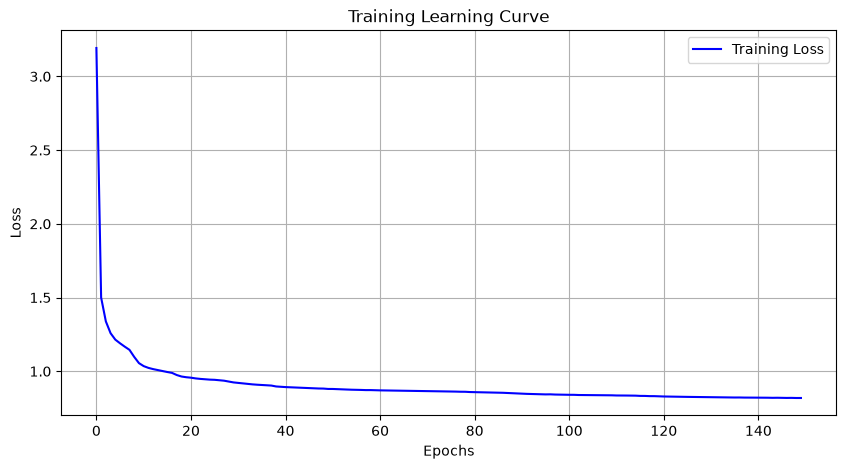

In [ ]:

# plt.figure(figsize=(10, 5))
# plt.plot(train_losses, label='Training Loss', color='blue')
# # plt.plot(valid_losses, label='Validation Loss', color='orange')  # Uncomment if you tracked validation loss

# plt.xlabel('Epochs')
# plt.ylabel('Loss')
# plt.title('Training Learning Curve')
# plt.legend()
# plt.grid(True)
# plt.show()

## training

In [57]:
# Model Training
model.to(device)  # Move model to GPU if available

epochs = 50
train_losses = []
valid_losses = []

for epoch in range(epochs):
    model.train()
    epoch_loss = 0

    for data, target in train_loader:
        data = data.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)  # target is not one-hot encoded in PyTorch
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    # Calculate average loss for this epoch
    train_losses.append(epoch_loss / len(train_loader))

    print(f'Epoch {epoch+1}/{epochs}, Loss: {train_losses[-1]:.4f}')

    # Validation step
    model.eval()
    valid_loss = 0
    with torch.no_grad():
        for data, target in val_loader:
            data = data.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)
            output = model(data)
            loss = criterion(output, target)
            valid_loss += loss.item()

    valid_losses.append(valid_loss / len(val_loader))
    print(f'Epoch {epoch+1}/{epochs}, Validation Loss: {valid_losses[-1]:.4f}')


Epoch 1/50, Loss: 0.0238
Epoch 1/50, Validation Loss: 0.0124
Epoch 2/50, Loss: 0.0122
Epoch 2/50, Validation Loss: 0.0110
Epoch 3/50, Loss: 0.0106
Epoch 3/50, Validation Loss: 0.0089
Epoch 4/50, Loss: 0.0098
Epoch 4/50, Validation Loss: 0.0091
Epoch 5/50, Loss: 0.0092
Epoch 5/50, Validation Loss: 0.0092
Epoch 6/50, Loss: 0.0089
Epoch 6/50, Validation Loss: 0.0083
Epoch 7/50, Loss: 0.0086
Epoch 7/50, Validation Loss: 0.0081
Epoch 8/50, Loss: 0.0084
Epoch 8/50, Validation Loss: 0.0081
Epoch 9/50, Loss: 0.0082
Epoch 9/50, Validation Loss: 0.0079
Epoch 10/50, Loss: 0.0080
Epoch 10/50, Validation Loss: 0.0081
Epoch 11/50, Loss: 0.0079
Epoch 11/50, Validation Loss: 0.0077
Epoch 12/50, Loss: 0.0078
Epoch 12/50, Validation Loss: 0.0077
Epoch 13/50, Loss: 0.0077
Epoch 13/50, Validation Loss: 0.0076
Epoch 14/50, Loss: 0.0076
Epoch 14/50, Validation Loss: 0.0075
Epoch 15/50, Loss: 0.0076
Epoch 15/50, Validation Loss: 0.0072
Epoch 16/50, Loss: 0.0075
Epoch 16/50, Validation Loss: 0.0074
Epoch 17/5

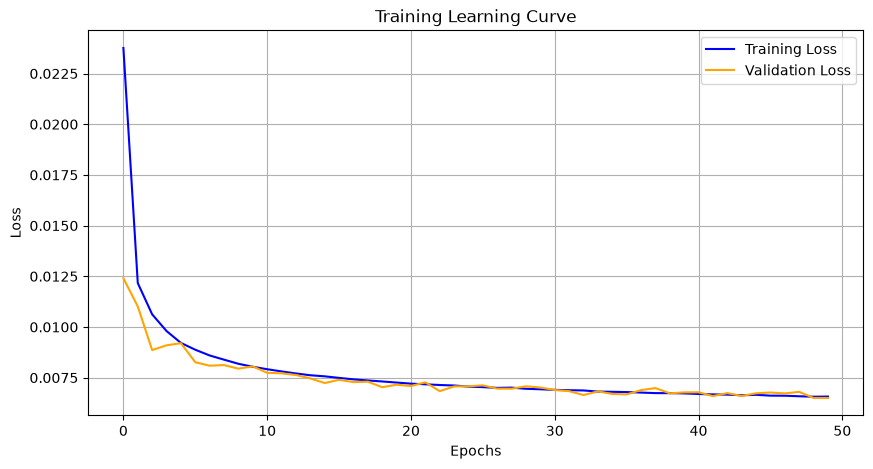

In [58]:

plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Training Loss', color='blue')
plt.plot(valid_losses, label='Validation Loss', color='orange') 
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Learning Curve')
plt.legend()
plt.grid(True)
plt.show()

# Save Model

In [59]:

os.makedirs("../ml_models", exist_ok=True)

#Timestamp
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")

model_path = f"../ml_models/arm_model_weights_{stamp}.pth"
torch.save(model.state_dict(), model_path)
print(f"Model weights saved to {model_path}")

Model weights saved to ../ml_models/arm_model_weights_20261103_1940.pth


# Load Model

In [ ]:
# 1. Initialize your model architecture first
model = MLP()  # Replace with your actual model class/architecture

# 2. Load the saved weights into the model
model.load_state_dict(torch.load("../ml_models/arm_model_weights_20261103_1940.pth"))

# 3. Move to device and set to evaluation mode if doing inference
model = model.to(device)
model.eval()

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=24, out_features=256, bias=True)
  (bn1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=256, out_features=256, bias=True)
  (bn2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=256, out_features=128, bias=True)
  (bn3): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu3): ReLU()
  (fc4): Linear(in_features=128, out_features=128, bias=True)
  (bn4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu4): ReLU()
  (fco): Linear(in_features=128, out_features=7, bias=True)
)

In [65]:
test_loss = 0

with torch.no_grad():
    
    for data, target in test_loader:
        data = data.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)
        output = model(data)
        test_loss += criterion(output, target).item()

test_loss /= len(test_loader)

print(f'Test Loss: {test_loss:.4f}')

Test Loss: 0.0066


In [72]:
data.shape, target.shape, output.shape

(torch.Size([2048, 24]), torch.Size([2048, 7]), torch.Size([183, 7]))

In [81]:
len(data[0]), len(train_labels[1:-7])
data[0], train_labels[1:-7]

(tensor([-4.8863e+00,  2.8429e+00,  1.9424e+00, -3.6500e-03,  9.9861e-01,
          2.0794e-04,  8.4791e-01, -2.3020e-03,  8.4150e-01,  4.8762e-04,
          9.9999e-01,  5.2669e-02,  1.0000e+00,  5.3014e-01,  1.0000e+00,
          5.4025e-01,  1.0000e+00,  1.0512e-01,  2.0317e-01, -9.2058e-03,
         -1.3879e-01,  2.8289e-02, -2.2669e-01, -8.0688e-03]),
 array(['pos_error_x', 'pos_error_y', 'pos_error_z', 'j1_sin', 'j2_sin',
        'j3_sin', 'j4_sin', 'j5_sin', 'j6_sin', 'j7_sin', 'j1_cos',
        'j2_cos', 'j3_cos', 'j4_cos', 'j5_cos', 'j6_cos', 'j7_cos',
        'j1_vel', 'j2_vel', 'j3_vel', 'j4_vel', 'j5_vel', 'j6_vel',
        'j7_vel'], dtype='<U11'))

In [75]:
364727 % 2048

183

In [86]:
# Test on one datapoint
data_point = X_test_tensor[0].unsqueeze(0).to(device)
with torch.no_grad():
    prediction = model(data_point)

data_point, prediction

(tensor([[-4.8863e+00,  2.8429e+00,  1.9424e+00, -3.6500e-03,  9.9861e-01,
           2.0794e-04,  8.4791e-01, -2.3020e-03,  8.4150e-01,  4.8762e-04,
           9.9999e-01,  5.2669e-02,  1.0000e+00,  5.3014e-01,  1.0000e+00,
           5.4025e-01,  1.0000e+00,  1.0512e-01,  2.0317e-01, -9.2058e-03,
          -1.3879e-01,  2.8289e-02, -2.2669e-01, -8.0688e-03]], device='cuda:0'),
 tensor([[-0.0319, -0.0012,  0.0297,  0.2008,  0.0577, -0.3322, -0.0168]],
        device='cuda:0'))

In [66]:
for data, target in test_loader:
    print("Data shape:", data.shape)
    print("Target shape:", target.shape)
    print("First data point:", data[0, :])
    break  # Only take the first batch for demonstration

Data shape: torch.Size([2048, 24])
Target shape: torch.Size([2048, 7])
First data point: tensor([-4.8863e+00,  2.8429e+00,  1.9424e+00, -3.6500e-03,  9.9861e-01,
         2.0794e-04,  8.4791e-01, -2.3020e-03,  8.4150e-01,  4.8762e-04,
         9.9999e-01,  5.2669e-02,  1.0000e+00,  5.3014e-01,  1.0000e+00,
         5.4025e-01,  1.0000e+00,  1.0512e-01,  2.0317e-01, -9.2058e-03,
        -1.3879e-01,  2.8289e-02, -2.2669e-01, -8.0688e-03])
